# HW3 demo: human / ai / fusion text classification — the whole pipeline on a mini sample

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BodiyaKol/ucu-ai-hw3-ai-text-detection_Kolodchak/blob/main/code/notebooks/demo_pipeline.ipynb)

**Run anywhere:** open the badge (Colab, CPU runtime is enough) or any Jupyter, then *Run all* — nothing else
is needed. The first cell clones this repo if the notebook is opened outside it; step 0 downloads the mini sample
(1.5k / 300 texts of the GhostWriter data, CC BY-NC-SA 4.0, course use only) from Google Drive. If that link is
unavailable, it falls back to the Kaggle API (then a `kaggle.json` token and accepted competition rules are needed).

This notebook re-runs **every step of the final pipeline** on a small sample (~1.5k texts, CPU, ~5 min)
to show that the code in this repo works end to end. Full-scale runs were done in Kaggle kernels
(`code/notebooks/0*_*/`); their results are loaded at the end.

| Step | Script | Full-scale run |
|---|---|---|
| 0. Data + format check | `make_mini.py`, `check_data.py` | Kaggle CPU `hw3-00-data` |
| 1. Preparation: stats, near-duplicates, grouped split | `build_annotations.py`, `build_similarity.py`, `make_split.py` | Kaggle CPU + local |
| 2. Model 1: TF-IDF char+word n-grams + LogReg | `train_tfidf.py` | Kaggle CPU, 150k texts |
| 3. Model 2: XLM-R (whole text via 512-token chunks) | `train_encoder.py` | Kaggle T4, 100k texts, 3 epochs |
| 4. Model 3: mDeBERTa-v3 specialist human vs fusion | `train_encoder.py` | Kaggle T4, 60k texts |
| 5. Ensemble (weights tuned with grouped cross-fit) | `ensemble_final.py` | local |

Requirements: the venv from `code/requirements.txt`. If `code/data/mini` is missing, step 0 downloads
the competition data (needs `~/.kaggle/kaggle.json` and accepted competition rules).
On the mini sample the transformers are **tiny random 1-layer models** (CPU), so their scores are
meaningless: the goal is to check that data flows through every step, not quality.

In [ ]:
import json
import os
import re
import subprocess
import sys
import zipfile
from pathlib import Path

REPO_URL = "https://github.com/BodiyaKol/ucu-ai-hw3-ai-text-detection_Kolodchak.git"
REPO_NAME = "ucu-ai-hw3-ai-text-detection_Kolodchak"
IN_COLAB = "google.colab" in sys.modules


def find_code_dir():
    for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / REPO_NAME / "code"):
        if (p / "scripts" / "train_encoder.py").exists():
            return p
    return None


CODE = find_code_dir()
if CODE is None:  # opened outside the repo (Colab / any Jupyter): clone it next to the notebook
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL], check=True)
    CODE = Path.cwd() / REPO_NAME / "code"
    # install only what is usually missing; torch/transformers/sklearn/pandas come from the environment
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "kaggle", "sentencepiece",
                    "transformers", "scikit-learn", "matplotlib", "scipy", "gdown"], check=True)
    try:
        import torch  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch",
                        "--index-url", "https://download.pytorch.org/whl/cpu"], check=True)
os.chdir(CODE)
print("working dir:", CODE)

import pandas as pd  # noqa: E402
from IPython.display import Image, display  # noqa: E402


def run(cmd: str, keep: str = None):
    """Run a repo script; print only lines matching the regex `keep` (short, readable output)."""
    env = {k: v for k, v in os.environ.items() if k != "KAGGLE_KERNEL_RUN_TYPE"}  # outputs always in code/outputs
    res = subprocess.run([sys.executable, *cmd.split()], capture_output=True, text=True, env=env)
    lines = (res.stdout + res.stderr).splitlines()
    for line in lines:
        if keep is None or re.search(keep, line):
            print(line)
    if res.returncode != 0:
        print("\n".join(lines[-20:]))
        raise RuntimeError(f"failed: {cmd}")


def ensure_kaggle_credentials():
    """kaggle.json in ~/.kaggle or KAGGLE_USERNAME/KAGGLE_KEY; in Colab ask to upload the file."""
    token = Path.home() / ".kaggle" / "kaggle.json"
    if token.exists() or os.environ.get("KAGGLE_USERNAME"):
        return
    if IN_COLAB:
        from google.colab import files
        print("Upload your kaggle.json (Kaggle -> Settings -> API -> Create New Token):")
        uploaded = files.upload()
        token.parent.mkdir(exist_ok=True)
        token.write_bytes(uploaded["kaggle.json"])
        token.chmod(0o600)
    else:
        raise RuntimeError("Put kaggle.json into ~/.kaggle/ or set KAGGLE_USERNAME and KAGGLE_KEY")

## 0. Data and format check
The mini sample is a uniform random 1.5k / 300 subset of train / test (`make_mini.py`).
`check_data.py` verifies ids, labels, missing texts and the `sample_submission` order.
**Read:** `rows=` per split, `checks: ... sample_order_matches_test: True, train_test_id_overlap: 0, unknown_labels: []`.

In [ ]:
# Mini sample (1.5k train / 300 test texts) published for graders as a zip on Google Drive.
# Source: GhostWriter (Schaaf, Bönisch, Mehler, LREC 2026), license CC BY-NC-SA 4.0, course use.
MINI_DRIVE_ID = "1D-cYqUNucfTd0SSkS1hj8P3EztJfcaen"
SLUG = "ai-generated-text-detection-hw3-ucu-ai-2026"
mini_dir = CODE / "data/mini"


def mini_from_drive() -> bool:
    try:
        import gdown
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
    mini_dir.mkdir(parents=True, exist_ok=True)
    zip_path = gdown.download(id=MINI_DRIVE_ID, output=str(CODE / "data/mini_data.zip"), quiet=True)
    if not zip_path:
        return False
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(mini_dir)
    return (mini_dir / "train.csv").exists()


def mini_from_kaggle():  # fallback: needs your own kaggle.json and accepted competition rules
    if not (CODE / "data/raw/train.csv").exists():
        ensure_kaggle_credentials()
        subprocess.run(["kaggle", "competitions", "download", "-c", SLUG, "-p", "data/raw"], check=True)
        with zipfile.ZipFile(CODE / f"data/raw/{SLUG}.zip") as z:
            z.extractall(CODE / "data/raw")
    run("scripts/make_mini.py", keep=r"mini:")


if not (mini_dir / "train.csv").exists():
    try:
        ok = mini_from_drive()
    except Exception as e:  # network / quota / wrong id
        print("Google Drive download failed:", e)
        ok = False
    if not ok:
        print("-> falling back to the Kaggle API")
        mini_from_kaggle()
run("scripts/check_data.py --mini", keep=r"^== (train|test):|== checks")

## 1. Data preparation
1. **Annotations** – per-text length/style statistics and token counts (no text), used for EDA.
2. **Near-duplicates** – for every text: 5 nearest neighbours (TF-IDF → SVD cosine, within language × domain),
   verified by word 3-gram Jaccard. Fusion texts are rewrites of human texts (Jaccard ≈ 0.55), AI texts are not.
3. **Grouped split** – texts linked by Jaccard > 0.2 form a group (connected components); `StratifiedGroupKFold`
   keeps every group on one side, so a fusion text and its human source are never split between train and val.

**Read:** `group overlap: ... = 0` (no leakage) and `random split: share of val rows with a related text in train`
(what a random split would leak; on the full data 0.467).

In [4]:
run("scripts/build_annotations.py --mini --tokenizers xlmr", keep=r"saved|n_tok_xlmr:")
run("scripts/build_similarity.py --mini", keep=r"saved|share of queries")
run("scripts/make_split.py --mini", keep=r"train rows|group overlap|random split|saved")

saved /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/annotations/annotations_mini.csv.gz rows=1798 cols=22 in 2s
n_tok_xlmr: median=648 share>512=0.629 share>1024=0.231
saved /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/similarity/pairs_mini.csv.gz rows=8975 in 3s
test: share of queries with best Jaccard > thr: {0.05: 0.013, 0.1: 0.01, 0.2: 0.007, 0.3: 0.003, 0.5: 0.0}
train: share of queries with best Jaccard > thr: {0.05: 0.027, 0.1: 0.015, 0.2: 0.003, 0.3: 0.003, 0.5: 0.003}
train rows=1498 edges=4 groups=1496 singletons=1494
group overlap: train-sample/val-sample=0 train-pool/val-pool=0
random split: share of val rows with a related text in train = 0.003 {'ai': 0.0, 'fusion': 0.0, 'human': 0.014}
saved /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/split/split_mini.csv.gz  train=1198 val=300


### EDA figures (full data, produced by `scripts/run_eda.py`)
Left: best-neighbour Jaccard — related texts exist only inside train (human/fusion), never test→train.
Right: style features keep the same class order inside every domain.

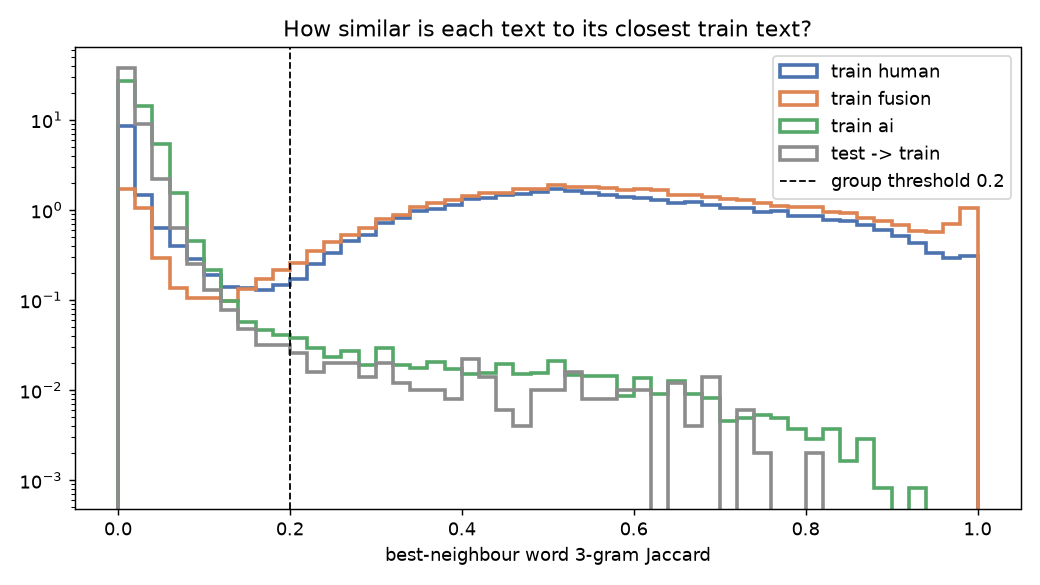

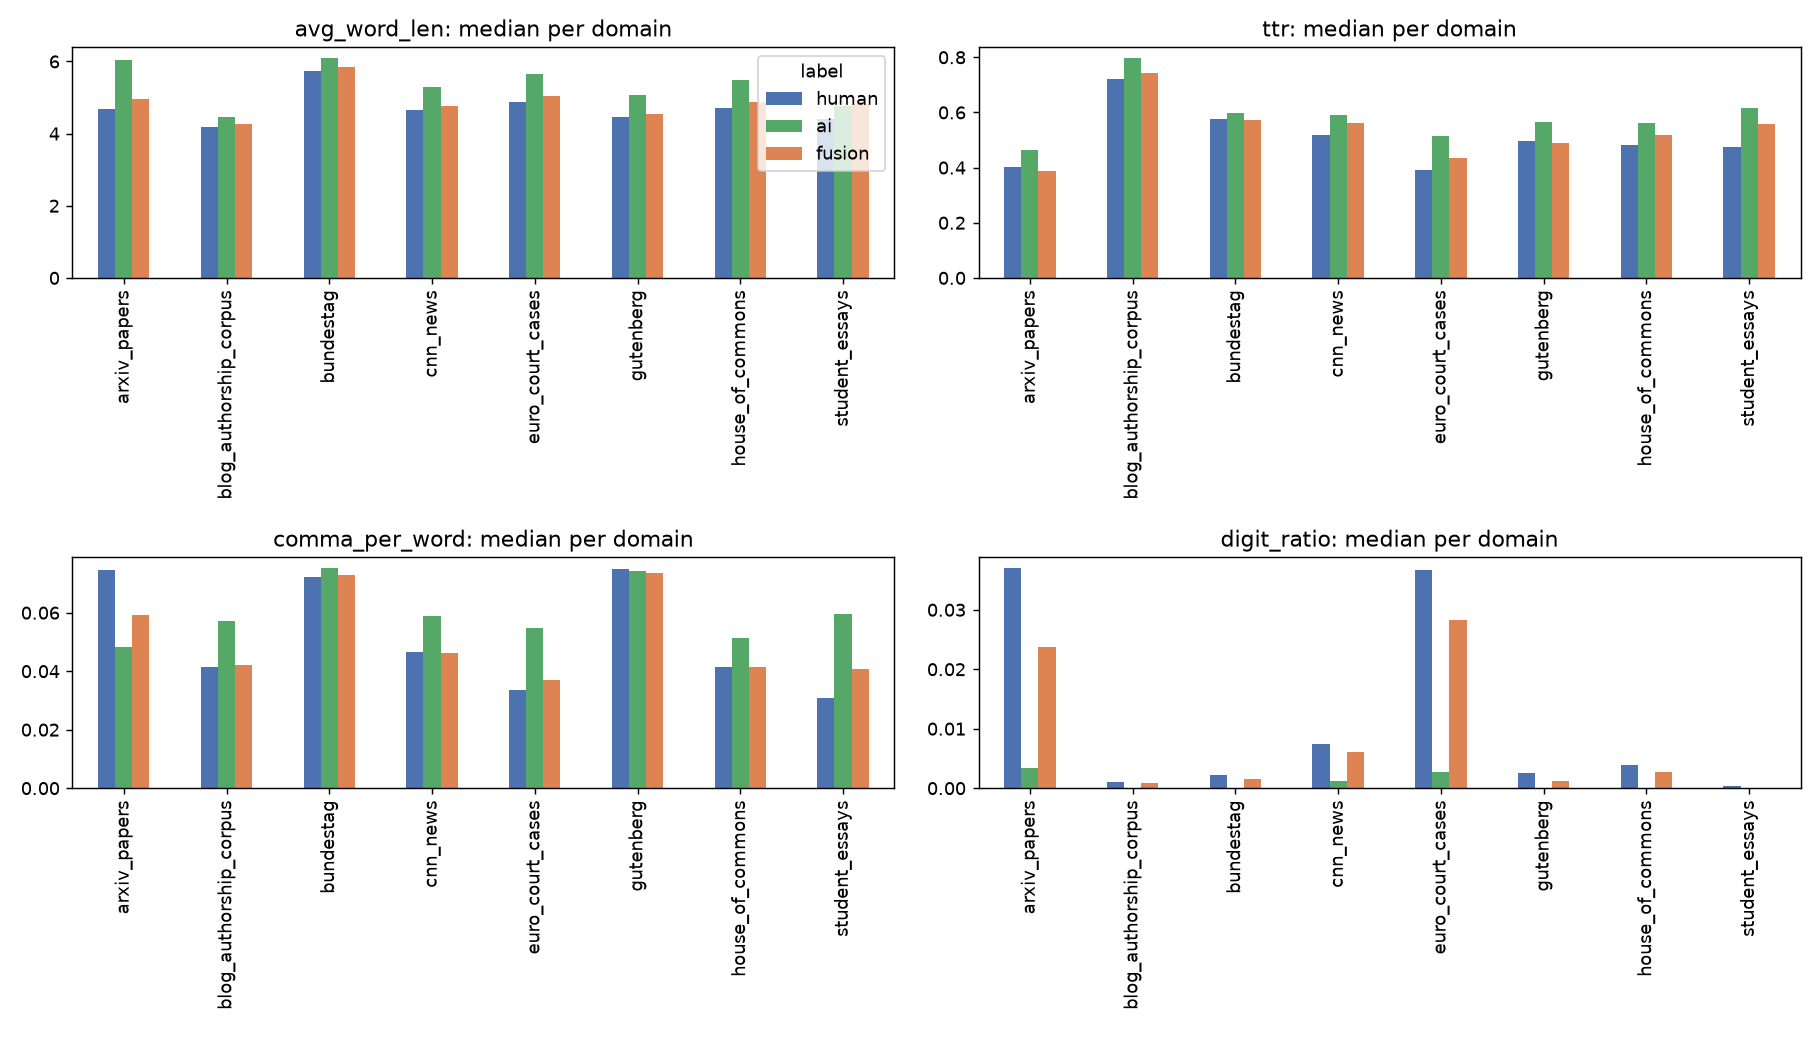

In [5]:
display(Image("results/figures/eda_jaccard.png", width=600))
display(Image("results/figures/eda_style_by_domain.png", width=800))

## 2. Model 1 — TF-IDF (char 3–5 + word 1–2 n-grams, no lowercasing) + Logistic Regression
Sees surface style: typos, casing, digits, punctuation, corpus artifacts. Vectorizers are fitted on train only.
**Read:** `== best ... val macro-F1` and `per-class F1`; the run also writes `val_scores.csv` / `test_scores.csv`
used by the ensemble.

In [6]:
run("scripts/train_tfidf.py --mini --config configs/tfidf/pool.yaml", keep=r"train=|== best|per-class|submission")

train=1198 val=300 test=300 -> /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/m4_tfidf_pool_mini
== best logreg C=10.0: val macro-F1 = 0.7378
per-class F1: {'human': 0.6351, 'ai': 0.9455, 'fusion': 0.6328}
submission OK, predicted label share on test: {'ai': 0.537, 'human': 0.253, 'fusion': 0.21}


## 3. Model 2 — XLM-R (multilingual transformer, sees the whole text)
Texts are split into 510-token chunks; logits of all chunks (≤ 8) are averaged (`eval mode chunks`).
`xlmr.yaml` = first run (50k, 2 epochs, head training); `xlmr_v2.yaml` = final run (100k, 3 epochs, a random chunk
per text in every epoch). **Read:** `epoch N: val macro-F1`, `mode chunks: ... windows=` (more windows than texts =
chunking works), `saved`.

In [7]:
for cfg in ("configs/encoder/xlmr.yaml", "configs/encoder/xlmr_v2.yaml"):
    run(f"scripts/train_encoder.py --mini --config {cfg}", keep=r"device=|== epoch|== mode|saved")

device=cpu fp16=False model=FacebookAI/xlm-roberta-base labels=['human', 'ai', 'fusion'] train=64 {'ai': 32, 'human': 21, 'fusion': 11} val=48 (eval rows 48) test=32 -> /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/m3_xlmr_mini
== epoch 0: val macro-F1 (head, 3 classes) = 0.2029
== mode head: val macro-F1 = 0.2029 windows=48 F1={'human': 0.0, 'ai': 0.6087, 'fusion': 0.0} (0s)
== mode head_tail: val macro-F1 = 0.2029 windows=48 F1={'human': 0.0, 'ai': 0.6087, 'fusion': 0.0} (0s)
== mode chunks: val macro-F1 = 0.2029 windows=349 F1={'human': 0.0, 'ai': 0.6087, 'fusion': 0.0} (0s)
saved /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/m3_xlmr_mini/metrics.json
device=cpu fp16=False model=FacebookAI/xlm-roberta-base labels=['human', 'ai', 'fusion'] train=64 {'ai': 30, 'fusion': 20, 'human': 14} val=48 (eval rows 48) test=32 -> /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_K

## 4. Model 3 — mDeBERTa-v3 specialist: human vs fusion only
Trained only on the hard pair (AI texts removed); 2 classes. In the ensemble it only re-splits the
human/fusion probability mass. **Read:** `labels=['human', 'fusion']`, train without `ai`, `(eval rows N)`.

In [8]:
run("scripts/train_encoder.py --mini --config configs/encoder/mdeberta_hf.yaml", keep=r"device=|== epoch|== mode|saved")

device=cpu fp16=False model=microsoft/mdeberta-v3-base labels=['human', 'fusion'] train=64 {'fusion': 35, 'human': 29} val=48 (eval rows 27) test=32 -> /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/m4_mdeberta_hf_mini
== epoch 0: val macro-F1 (head, 2 classes) = 0.3250
== mode chunks: val macro-F1 = 0.3250 windows=351 F1={'human': 0.65, 'fusion': 0.0} (0s)
saved /home/bohdan/3_course/AI-3-course/HW3_NLP/ucu-ai-hw3-ai-text-detection_Kolodchak/code/outputs/m4_mdeberta_hf_mini/metrics.json


## 5. Ensemble
`p = w1·TF-IDF + w2·XLM-R(m3) + w3·XLM-R(v2)` (weights on a 0.1 grid), then hierarchical specialist:
P(ai) from the blend, the human/fusion split mixed with mDeBERTa (`a`). Parameters are tuned on one grouped
half of val and evaluated on the other (**[honest]** rows). **Read:** the `[honest]` column `macro_f1`.

In [9]:
run("scripts/ensemble_final.py --mini", keep=r"available|single|\[honest\]|best honest")

available: ['spec', 'tfidf', 'xlmr_m3', 'xlmr_v2']
                               single tfidf    0.7372    0.6207 0.9756     0.6154                                                                                            
                             single xlmr_m3    0.2029    0.0000 0.6087     0.0000                                                                                            
                             single xlmr_v2    0.2029    0.0000 0.6087     0.0000                                                                                            
     tfidf+xlmr_m3 (previous best) [honest]    0.7372    0.6207 0.9756     0.6154                                               tfidf=0.1 xlmr_m3=0.9 | tfidf=0.1 xlmr_m3=0.9
                     tfidf+xlmr_v2 [honest]    0.7372    0.6207 0.9756     0.6154                                               tfidf=0.1 xlmr_v2=0.9 | tfidf=0.1 xlmr_v2=0.9
             tfidf+xlmr_m3+xlmr_v2 [honest]    0.7372    0.6207 0.9756     0.61

## 6. Full-scale results (Kaggle runs, committed in `results/`)

In [10]:
final = json.load(open("results/m4_final/metrics.json"))
display(pd.DataFrame(final["table"])[["experiment", "macro_f1", "f1_human", "f1_ai", "f1_fusion"]])

lb = pd.DataFrame([
    ("m2 TF-IDF 50k", 0.8816, 0.87608, 0.86929),
    ("m3 XLM-R chunks", 0.8975, 0.89004, 0.89723),
    ("E1 TF-IDF 50k + XLM-R", 0.9180, 0.91661, 0.91546),
    ("E1 TF-IDF 150k + XLM-R", 0.9267, 0.92636, 0.92185),
    ("sub_1: TF-IDF 150k + XLM-R v2 (selected)", 0.9456, 0.94207, 0.94388),
    ("sub_4: + XLM-R m3 + mDeBERTa specialist (selected)", 0.9477, 0.94585, 0.94834),
], columns=["submission", "val macro-F1", "public LB", "private LB"])
display(lb)

,experiment,macro_f1,f1_human,f1_ai,f1_fusion
0,single tfidf,0.9019,0.8554,0.9872,0.8631
1,single xlmr_m3,0.8975,0.8368,0.9851,0.8706
2,single xlmr_v2,0.9274,0.8790,0.9925,0.9106
3,tfidf+xlmr_m3 (previous best) [honest],0.9263,0.8853,0.9920,0.9015
4,tfidf+xlmr_v2 [honest],0.9456,0.9143,0.9933,0.9292
5,tfidf+xlmr_m3+xlmr_v2 [honest],0.9453,0.9137,0.9932,0.9291
6,tfidf+xlmr_v2 + specialist [honest],0.9470,0.9179,0.9923,0.9307
7,tfidf+xlmr_m3+xlmr_v2 + specialist [honest],0.9477,0.9177,0.9936,0.9319


,submission,val macro-F1,public LB,private LB
0,m2 TF-IDF 50k,0.8816,0.87608,0.86929
1,m3 XLM-R chunks,0.8975,0.89004,0.89723
2,E1 TF-IDF 50k + XLM-R,0.9180,0.91661,0.91546
3,E1 TF-IDF 150k + XLM-R,0.9267,0.92636,0.92185
4,sub_1: TF-IDF 150k + XLM-R v2 (selected),0.9456,0.94207,0.94388
5,sub_4: + XLM-R m3 + mDeBERTa specialist (selec...,0.9477,0.94585,0.94834


## Conclusion

**Pipeline.** Three different views of a text were combined. *TF-IDF on character and word n-grams* captures
surface style — typos, casing, digits, punctuation and corpus artifacts that human (and fusion) texts carry and
AI texts do not; it was trained on 150k texts. *XLM-R* reads the text in context and, through 512-token chunks with
averaged logits, sees the whole document, which matters because an LLM rewrites fusion texts in local spans;
it was trained on 100k texts for 3 epochs with a random chunk per text per epoch. *mDeBERTa-v3* was trained only on
human vs fusion, the pair that causes almost all errors (AI is recognised with F1 ≈ 0.99), and is used to re-split
the human/fusion probability.

**Validation.** All comparisons use one fixed split built from near-duplicate groups, so a fusion text and its
human source never sit on different sides — a random split would place 47 % of validation texts next to a relative
in train. Ensemble weights were tuned on one half of validation and scored on the other.

**Leaderboard.** Each step improved both validation and leaderboard: TF-IDF 0.869 → XLM-R 0.897 → first ensemble
0.915 → more data for both models 0.944 → final ensemble with the specialist **0.948 (private)**. The two selected
submissions are the final ensemble (`sub_4`, private 0.94834) and the simpler TF-IDF + XLM-R v2 blend (`sub_1`,
private 0.94388). Validation (0.9477) matched the private score within 0.001, so the protocol was reliable.